# Chronos-2: Zero-Shot Forecasting for a BIM Digital Twin

### HRU507 / S-L5-008 — Temperature, Humidity and CO₂

**Research objective:** predict values at **5, 10, and 15 minutes ahead** on the one-minute aligned hybrid sensor dataset. Compare **pretrained Chronos-2** (not a chatbot or RAG system) with **persistence** and eventually a custom-trained Transformer.

**中文概念：**Chronos-2 是已经预训练好的时间序列预测 AI。我们提供过去 60/180 分钟的温度、湿度、CO₂ 数据，让它直接预测未来 15 分钟，**不用在自己的数据上从零训练**。

**Strict data-provenance note:** Temperature is a proxy using an assumed Fahrenheit original channel; RH and CO₂ are *simulated*. The experiment **does not prove physical sensor accuracy**. See `README.md` and `RESEARCH_NOTES.md`.

The notebook uses readable functions from **`main.py`** (the standalone executable). Every plot and numerical summary below can be reproduced with that script.

## 1. Local environment / 本地开发环境

Run this notebook **inside VS Code**, with the **Python** and **Jupyter** extensions and the project's `.venv` kernel selected. No Google Colab, no Google Drive mounting, no web Jupyter service.

**Installation (one-time in the VS Code terminal, NOT a notebook code cell):**

- Windows: `py -3.11 -m venv .venv`, activate via `.\.venv\Scripts\Activate.ps1`.
- macOS/Linux: `python3.11 -m venv .venv`, then `source .venv/bin/activate`.
- Install PyTorch according to your CPU/CUDA/MPS device at https://pytorch.org/get-started/locally/ . For a Windows CPU, `python -m pip install torch --index-url https://download.pytorch.org/whl/cpu`.
- `python -m pip install -r requirements.txt`
- `python -m ipykernel install --user --name hru507-chronos2 --display-name "Python (HRU507 Chronos-2)"`

**Important:** First Chronos model load downloads pretrained weights from Hugging Face; the experiments thereafter use local inference. CPU is supported but may take longer. To run through terminal only, use `python main.py --device auto`.

**Best practice from uploaded tutorials:** organized imports, reproducibility, and transparent environment configuration—**not** their Colab-specific cells.

In [2]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
from IPython.display import display, Image
from main import (COLS, HORIZONS, Settings, load_dataset, chronological_splits,
                  origins_for_segment, choose_device, self_test, run,
                  load_chronos_pipeline, forecast_windows, score_forecasts)

pd.set_option('display.max_columns', 30)
print('Python:', sys.version.split()[0])
print('OS:', platform.platform())
print('Pandas:', pd.__version__)
print('Project folder:', Path.cwd())
assert Path('main.py').exists(), 'Open the unzipped experiment FOLDER in VS Code, not a different working directory.'

Python: 3.11.9
OS: Windows-10-10.0.26200-SP0
Pandas: 2.3.3
Project folder: c:\Users\User\Downloads\Chronos2_HRU507_Experiment\Chronos2_HRU507_Experiment


## 2. Load, validate and understand your source data / 读取并验证数据

**From `Data_loading.ipynb` and `regression.ipynb`:** check missing values, numeric columns, sizes and distributions before using data. Here we also enforce **exact 1-minute spacing**, ascending unique timestamps and one asset/sensor. We do **not** silently interpolate missing rows. No labels, future covariates or provenance fields are passed into the forecasting model.

In [3]:
CSV_PATH = Path('data/HRU507_S-L5-008_1min_aligned.csv')
if not CSV_PATH.exists():
    raise FileNotFoundError('First copy your original uploaded CSV into the project/data folder. See README.md.')

df = load_dataset(CSV_PATH)
print('Rows:', f'{len(df):,}')
print('Date range:', df['timestamp'].min(), 'through', df['timestamp'].max())
print('Asset / Sensor:', df['asset_id'].iloc[0], df['sensor_id'].iloc[0])
display(df[['timestamp', *COLS]].head())
display(df[list(COLS)].describe().round(3))
print('Missing:', df[list(COLS)].isna().sum().to_dict())

Rows: 525,540
Date range: 2018-01-01 01:00:00 through 2018-12-31 23:59:00
Asset / Sensor: HRU507 S-L5-008


,timestamp,temperature_c,humidity_rh,co2_ppm
0,2018-01-01 01:00:00,23.3036,41.160,420.0
1,2018-01-01 01:01:00,23.3210,41.117,420.0
2,2018-01-01 01:02:00,23.3380,41.075,420.0
3,2018-01-01 01:03:00,23.3546,41.034,420.0
4,2018-01-01 01:04:00,23.3708,40.993,420.0


,temperature_c,humidity_rh,co2_ppm
count,525540.000,525540.000,525540.000
mean,22.701,45.944,599.720
std,3.329,7.667,174.544
min,17.836,13.463,420.000
25%,20.740,41.704,433.950
50%,21.901,47.535,532.270
75%,23.633,51.982,766.080
max,43.606,59.079,897.650


Missing: {'temperature_c': 0, 'humidity_rh': 0, 'co2_ppm': 0}


### 2.1 Check simulated-data provenance

The full CSV has **source metadata**, which must not be deleted or hidden in the research report. `temperature_provenance=source_ZONE_TEMP_1_assumed_F`, while `humidity_provenance` and `co2_provenance` specify simulation. **Observed proxy ≠ confirmed calibrated equipment sensor**.

In [4]:
for field in ('temperature_provenance','humidity_provenance','co2_provenance','dataset_type'):
    print(f'{field}: {df[field].value_counts(dropna=False).to_dict()}')

temperature_provenance: {'source_ZONE_TEMP_1_assumed_F': 525540}
humidity_provenance: {'synthetic_physical_mass_balance': 525540}
co2_provenance: {'synthetic_physical_mass_balance': 525540}
dataset_type: {'HYBRID_OBSERVED_PROXY_AND_SIMULATED': 525540}


### 2.2 Plot one day of real CSV rows / 可视化实际数据

Classification's accuracy/F1 is not appropriate here: these are **continuous measurements**, so we use regression forecasting and errors measured in each variable's physical unit.

In [5]:
import matplotlib.pyplot as plt
sample = df.iloc[:1440]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, col in zip(axes, COLS):
    ax.plot(sample['timestamp'], sample[col], linewidth=1)
    ax.set_ylabel(col)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel('Timestamp (sample of first 24 hours)')
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_37012\3248150386.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Chronological train / validation / test splits / 按时间分割

We do **70% / 15% / 15%** (time order). It is misleading to randomly shuffle a sequence when the purpose is future forecasting.

- **Train (past):** descriptive stats, per-variable scales, and baseline event thresholds; Chronos weights are *not fitted* here.
- **Validation:** choose whether 60 or 180 minutes of context works better; no future test results influence this choice.
- **Test:** one final held-out evaluation; forecasts may use **earlier observed history**, but never future targets.

中文：模型预测某一分钟之后的数值时，绝对不能先看到那个未来数值。

In [6]:
split = chronological_splits(len(df))
for name, (start, end) in split.items():
    print(name, f'{end-start:,} rows:', df['timestamp'].iloc[start], '→', df['timestamp'].iloc[end-1])
origin = split['test'][0]  # First timestamp in test is observed; shown for demonstration only.
context = 60
past = df.loc[origin-context+1:origin, list(COLS)].to_numpy().T
print('Example past-only tensor [3 variables,60 minutes]:', past.shape)
assert past.shape == (3,60)
print('Most recent input at:', df.timestamp.iloc[origin])
print('First FUTURE target (not an input):', df.timestamp.iloc[origin+1])

train 367,878 rows: 2018-01-01 01:00:00 → 2018-09-13 12:17:00
validation 78,831 rows: 2018-09-13 12:18:00 → 2018-11-07 06:08:00
test 78,831 rows: 2018-11-07 06:09:00 → 2018-12-31 23:59:00
Example past-only tensor [3 variables,60 minutes]: (3, 60)
Most recent input at: 2018-11-07 06:09:00
First FUTURE target (not an input): 2018-11-07 06:10:00


## 4. Pretrained Chronos-2 model / 加载预训练模型

Chronos-2 is an **encoder-only time-series foundation model** with *group attention* for joint multivariate forecasting. Its official API expects a tensor with dimensions `[number of forecast origins, number of variables, history length]`. We use three targets together and request 15-step-ahead forecasts, including **10%, 50%, 90% quantiles**. The 50% quantile is the point forecast.

We rely on the **official `Chronos2Pipeline.predict_quantiles`** method. No `.fit()`, backpropagation, learning rate tuning or custom attention layers.

**Device choice:** `auto` prefers NVIDIA CUDA, then Apple Silicon MPS, otherwise CPU. With an Intel Mac or no CUDA driver, CPU is normal. **No prediction is performed by the check below.**

In [7]:
try:
    DEVICE = choose_device('auto')
    print('Selected PyTorch device:', DEVICE)
except ImportError:
    print('PyTorch not installed. Finish installation in section 1.')

self_test()  # Uses a FAKE predictor only to check no future values are fed as inputs.

Selected PyTorch device: cpu
  Forecasted 2/2 origins
SELF-TEST PASS: correct window isolation, shapes, split boundaries. Fake outputs were NOT saved.


## 5. First run: honest persistence baseline / 先做简单的基线

Before spending time downloading the large model, run the **same evaluation** using a basic reference: **predict that every future minute equals the last observed value**. This is a legitimate, reproducible forecasting baseline.

The resulting scores are **NOT Chronos-2 results**. A new `outputs/` folder is created.

In [8]:
baseline_result = run(Settings(
    csv=str(CSV_PATH), output='outputs', mode='baseline',
    validation_origins=32, test_origins=64, event_origins=18
))
display(baseline_result['test_metrics'].round(4))

Dataset: 525,540 rows, 2018-01-01 01:00:00 to 2018-12-31 23:59:00
Chronological splits: {'train': (Timestamp('2018-01-01 01:00:00'), Timestamp('2018-09-13 12:17:00')), 'validation': (Timestamp('2018-09-13 12:18:00'), Timestamp('2018-11-07 06:08:00')), 'test': (Timestamp('2018-11-07 06:09:00'), Timestamp('2018-12-31 23:59:00'))}
Validation origins: 32 Test origins: 64
Baseline-only finished. No Chronos-2 predictions were generated.


,split,model,sensor,units,horizon_minutes,n_origins,mae,rmse,persistence_mae,persistence_rmse,mae_skill_vs_persistence,p10_p90_coverage
0,test,persistence_baseline,co2_ppm,ppm,5,64,1.7211,2.7981,1.7211,2.7981,0.0,None
1,test,persistence_baseline,co2_ppm,ppm,10,64,3.5888,5.7004,3.5888,5.7004,0.0,None
2,test,persistence_baseline,co2_ppm,ppm,15,64,5.6755,9.5538,5.6755,9.5538,0.0,None
3,test,persistence_baseline,humidity_rh,%RH,5,64,0.2036,0.6744,0.2036,0.6744,0.0,None
4,test,persistence_baseline,humidity_rh,%RH,10,64,0.4198,1.3680,0.4198,1.3680,0.0,None
5,test,persistence_baseline,humidity_rh,%RH,15,64,0.6468,2.0879,0.6468,2.0879,0.0,None
6,test,persistence_baseline,temperature_c,°C,5,64,0.0682,0.2673,0.0682,0.2673,0.0,None
7,test,persistence_baseline,temperature_c,°C,10,64,0.1381,0.5155,0.1381,0.5155,0.0,None
8,test,persistence_baseline,temperature_c,°C,15,64,0.2084,0.7533,0.2084,0.7533,0.0,None


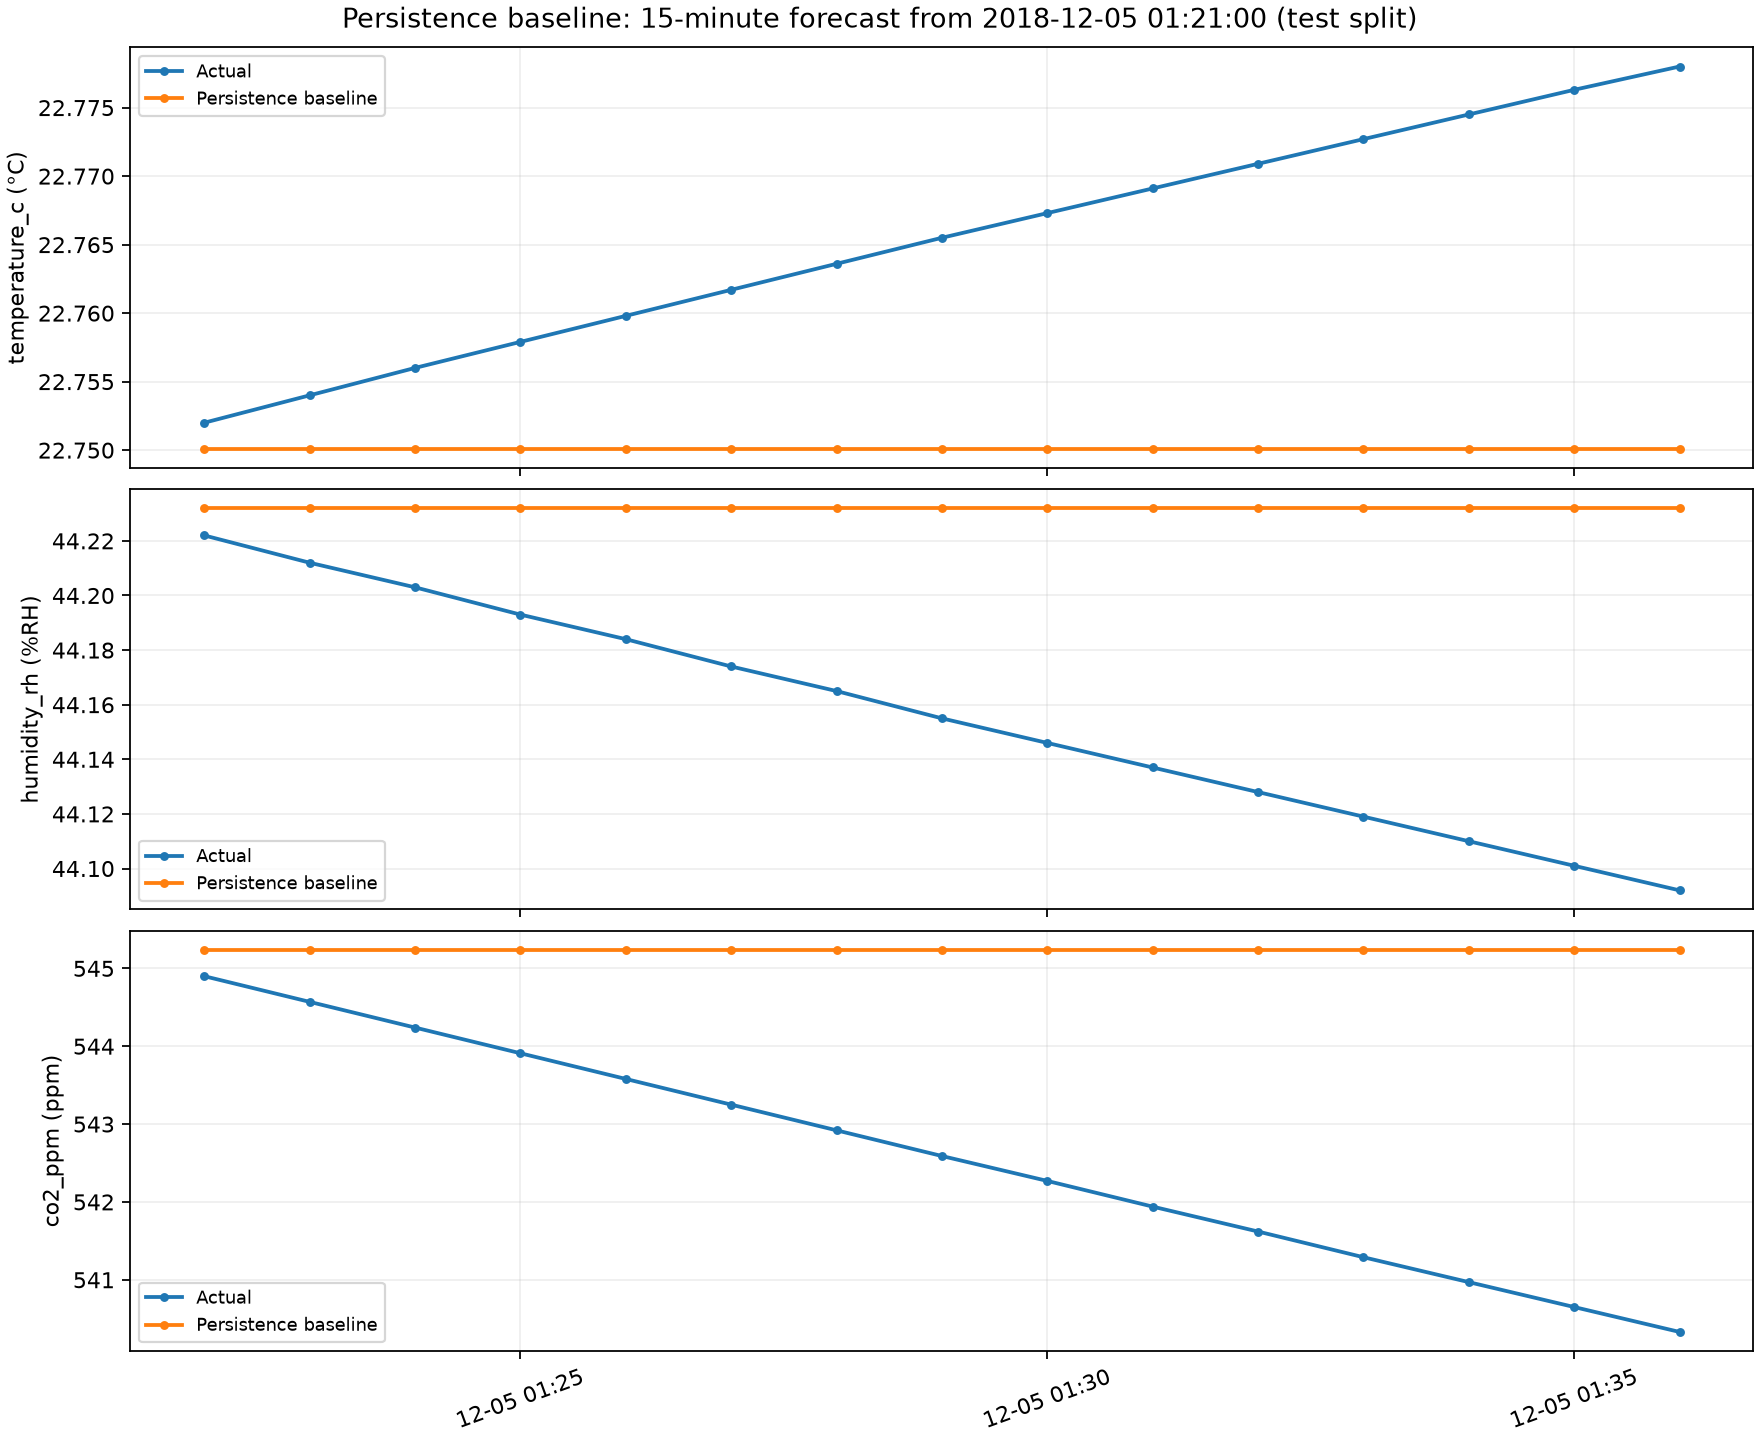

In [9]:
display(Image(filename='outputs/baseline_test_example.png', width=950))

## 6. Full Chronos-2 experiment / 正式预测实验

The **first run may download model weights**, requires internet for that initial download and may take some time on a CPU. Set `RUN_CHRONOS = False` to inspect the preceding steps without downloading. Leave it `True` to complete the actual experiment.

1. Load the pretrained model using the model ID `amazon/chronos-2`.
2. Independently evaluate **60** and **180** minutes of historical context on the **validation** period.
3. Choose context based on mean **normalized validation MAE**, equally weighting temperature, RH and CO₂.
4. Evaluate **held-out test** values for 5/10/15 minutes.
5. Save per-sensor MAE/RMSE, persistence scores, p10/p90 intervals and predicted paths.

**Important:** Default origins are sampled, NOT every minute. Increase counts once the code works on your hardware.

In [10]:
RUN_CHRONOS = True       # Change to False to skip model download/inference.
VALIDATION_ORIGINS = 32  # Later increase to 128 for more representative results.
TEST_ORIGINS = 64        # Later increase to 256 for a stronger final evaluation.

if RUN_CHRONOS:
    chronos_result = run(Settings(
        csv=str(CSV_PATH), output='outputs', mode='chronos',
        device='auto', context_candidates=(60, 180),
        validation_origins=VALIDATION_ORIGINS,
        test_origins=TEST_ORIGINS, event_origins=18,
        batch_size=6, model_id='amazon/chronos-2'
    ))
    display(chronos_result['test_metrics'].round(4))
else:
    print('Chronos-2 inference SKIPPED by user; no Chronos-2 results generated.')

Dataset: 525,540 rows, 2018-01-01 01:00:00 to 2018-12-31 23:59:00
Chronological splits: {'train': (Timestamp('2018-01-01 01:00:00'), Timestamp('2018-09-13 12:17:00')), 'validation': (Timestamp('2018-09-13 12:18:00'), Timestamp('2018-11-07 06:08:00')), 'test': (Timestamp('2018-11-07 06:09:00'), Timestamp('2018-12-31 23:59:00'))}
Validation origins: 32 Test origins: 64


c:\Users\User\Downloads\Chronos2_HRU507_Experiment\Chronos2_HRU507_Experiment\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading amazon/chronos-2 on cpu (first use downloads model weights)...


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 443.80it/s]

Validating context length 60 minutes...


  Forecasted 6/32 origins
  Forecasted 12/32 origins
  Forecasted 18/32 origins
  Forecasted 24/32 origins
  Forecasted 30/32 origins
  Forecasted 32/32 origins
Validating context length 180 minutes...
  Forecasted 6/32 origins
  Forecasted 12/32 origins
  Forecasted 18/32 origins
  Forecasted 24/32 origins
  Forecasted 30/32 origins
  Forecasted 32/32 origins
Chosen context (validation only): 60 minutes. Evaluating held-out test...
  Forecasted 6/64 origins
  Forecasted 12/64 origins
  Forecasted 18/64 origins
  Forecasted 24/64 origins
  Forecasted 30/64 origins
  Forecasted 36/64 origins
  Forecasted 42/64 origins
  Forecasted 48/64 origins
  Forecasted 54/64 origins
  Forecasted 60/64 origins
  Forecasted 64/64 origins
Evaluating 53 distinct transition origins...
  Forecasted 6/53 origins
  Forecasted 12/53 origins
  Forecasted 18/53 origins
  Forecasted 24/53 origins
  Forecasted 30/53 origins
  Forecasted 36/53 origins
  Forecasted 42/53 origins
  Forecasted 48/53 origins
  Forec

,split,model,sensor,units,horizon_minutes,n_origins,mae,rmse,persistence_mae,persistence_rmse,mae_skill_vs_persistence,p10_p90_coverage
0,test,chronos2_zero_shot,co2_ppm,ppm,5,64,0.1215,0.3239,1.7211,2.7981,0.9294,0.8906
1,test,chronos2_zero_shot,co2_ppm,ppm,10,64,0.5084,1.7604,3.5888,5.7004,0.8583,0.8906
2,test,chronos2_zero_shot,co2_ppm,ppm,15,64,1.1722,5.3000,5.6755,9.5538,0.7935,0.9062
3,test,chronos2_zero_shot,humidity_rh,%RH,5,64,0.1253,0.5965,0.2036,0.6744,0.3844,0.9219
4,test,chronos2_zero_shot,humidity_rh,%RH,10,64,0.2830,1.2717,0.4198,1.3680,0.3257,0.8125
5,test,chronos2_zero_shot,humidity_rh,%RH,15,64,0.4620,1.9749,0.6468,2.0879,0.2858,0.7969
6,test,chronos2_zero_shot,temperature_c,°C,5,64,0.0472,0.2337,0.0682,0.2673,0.3070,0.8906
7,test,chronos2_zero_shot,temperature_c,°C,10,64,0.1005,0.4702,0.1381,0.5155,0.2723,0.8125
8,test,chronos2_zero_shot,temperature_c,°C,15,64,0.1588,0.7033,0.2084,0.7533,0.2379,0.8125


## 7. Actual vs predicted visualization / 预测与真实值对比

Blue/green etc. lines are **actual test labels**, **Chronos p50 predictions**, and **persistence**. The shaded band represents model p10–p90 uncertainty (a nominal 80% interval, not guaranteed calibration).

To inspect more origins, read `outputs/chronos2_test_forecast_paths.csv`: every sampled origin contains an actual and predicted value for each step **1–15** and each sensor.

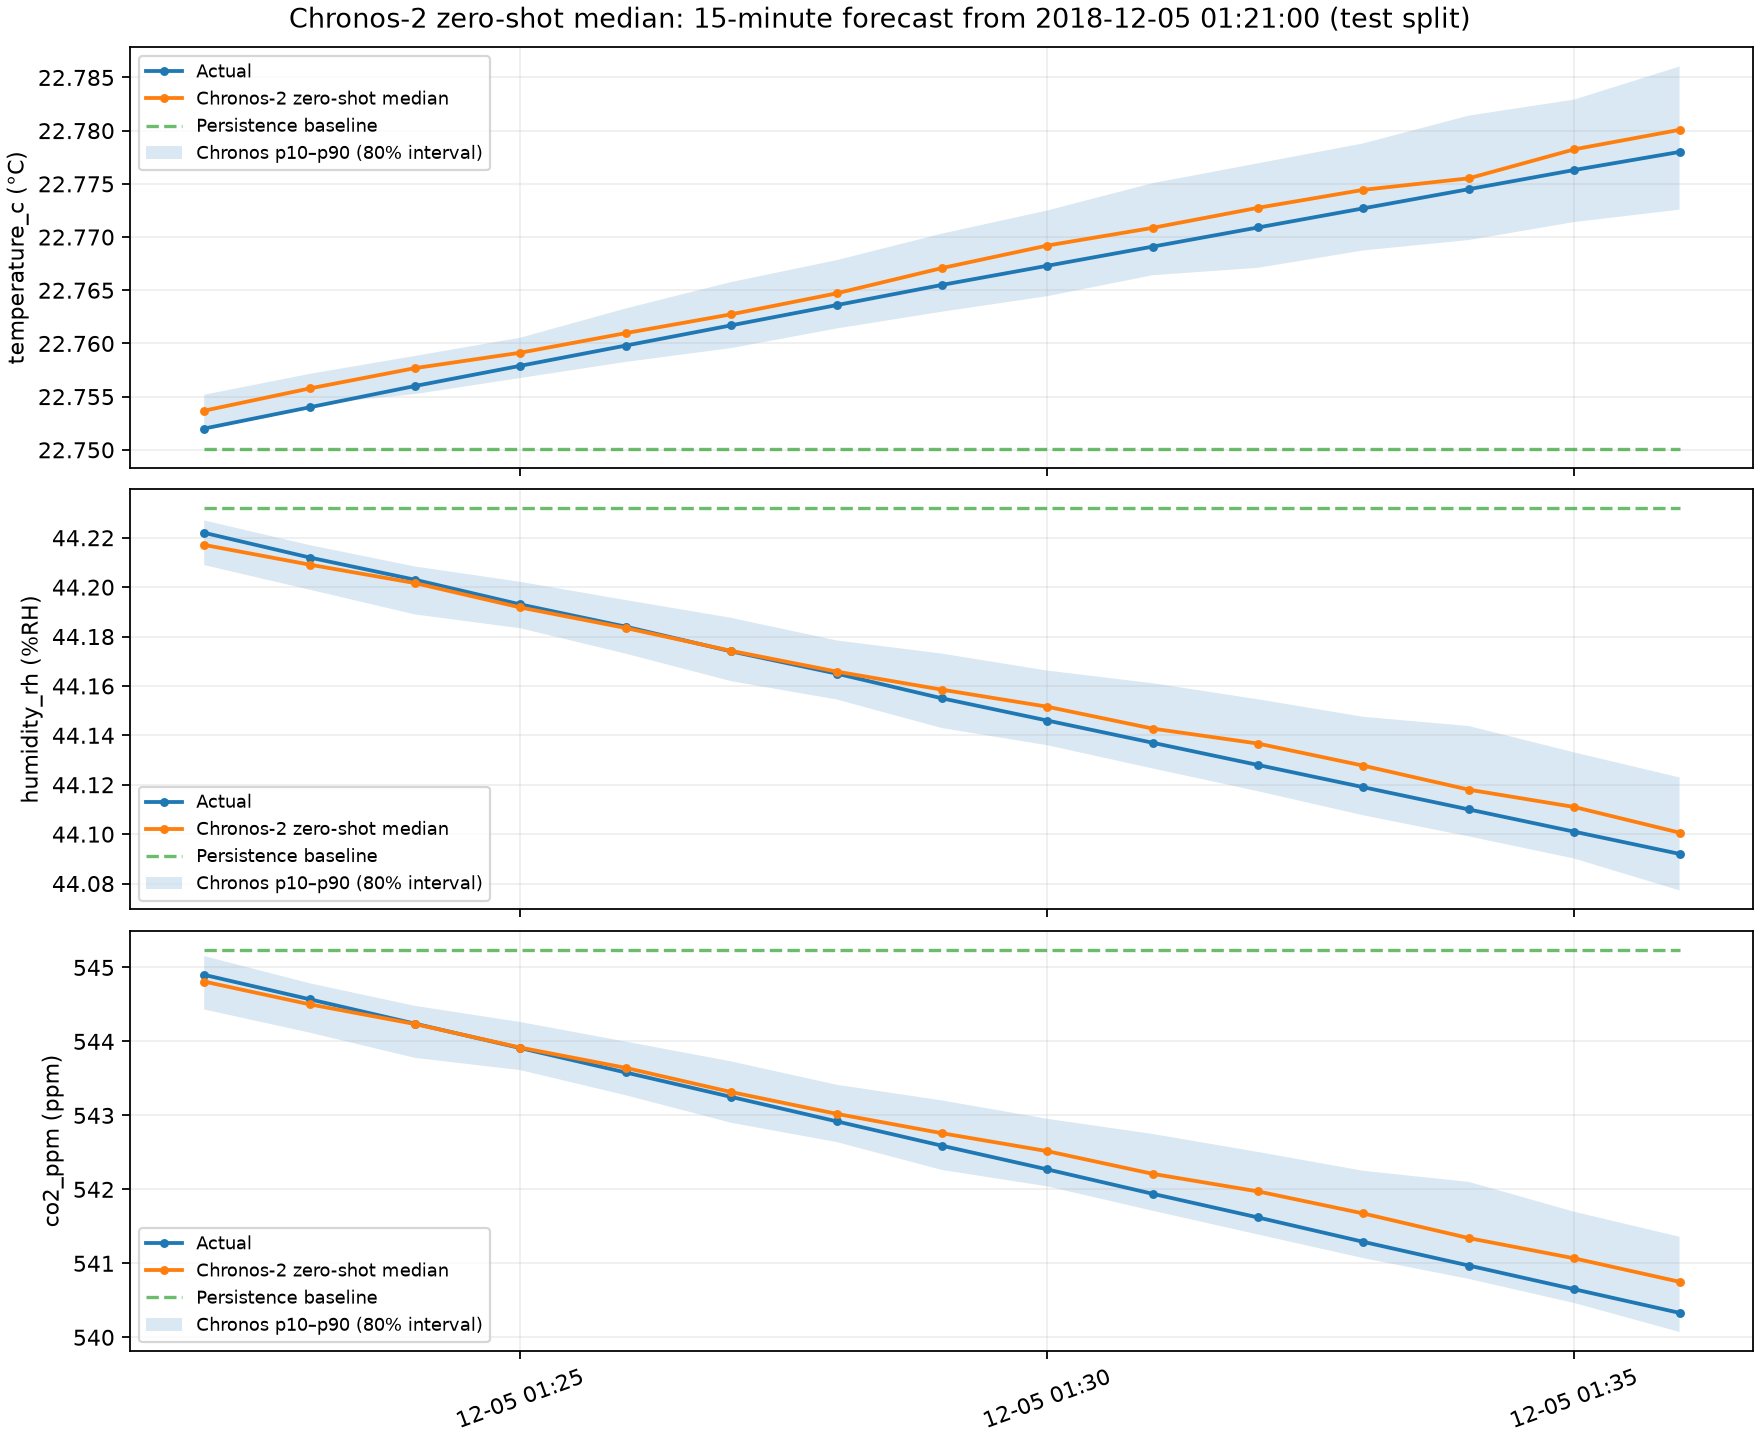

,split,model,origin_timestamp,target_timestamp,horizon_minutes,sensor,units,actual,predicted,p10,p50,p90,persistence
0,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:09:00,1,temperature_c,°C,24.2120,24.566502,24.415409,24.566502,25.806942,24.7012
1,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:10:00,2,temperature_c,°C,23.9175,24.548622,24.374983,24.548622,26.054146,24.7012
2,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:11:00,3,temperature_c,°C,23.4811,24.527679,24.360138,24.527679,26.322607,24.7012
3,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:12:00,4,temperature_c,°C,23.1211,24.519285,24.342533,24.519285,26.476093,24.7012
4,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:13:00,5,temperature_c,°C,22.7169,24.494493,24.345823,24.494493,26.698322,24.7012
5,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:14:00,6,temperature_c,°C,22.3562,24.484396,24.345966,24.484396,26.680550,24.7012
6,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:15:00,7,temperature_c,°C,21.9920,24.477528,24.337486,24.477528,26.749374,24.7012
7,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:16:00,8,temperature_c,°C,21.6596,24.478979,24.340376,24.478979,26.872808,24.7012
8,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:17:00,9,temperature_c,°C,21.3419,24.467882,24.334288,24.467882,26.853479,24.7012
9,test,chronos2_zero_shot,2018-11-07 06:08:00,2018-11-07 06:18:00,10,temperature_c,°C,21.0530,24.464666,24.340021,24.464666,26.861095,24.7012


,sensor,horizon_minutes,mae,rmse,persistence_mae,persistence_rmse,mae_skill_vs_persistence,p10_p90_coverage
0,co2_ppm,5,0.1215,0.3239,1.7211,2.7981,0.9294,0.8906
1,co2_ppm,10,0.5084,1.7604,3.5888,5.7004,0.8583,0.8906
2,co2_ppm,15,1.1722,5.3000,5.6755,9.5538,0.7935,0.9062
3,humidity_rh,5,0.1253,0.5965,0.2036,0.6744,0.3844,0.9219
4,humidity_rh,10,0.2830,1.2717,0.4198,1.3680,0.3257,0.8125
5,humidity_rh,15,0.4620,1.9749,0.6468,2.0879,0.2858,0.7969
6,temperature_c,5,0.0472,0.2337,0.0682,0.2673,0.3070,0.8906
7,temperature_c,10,0.1005,0.4702,0.1381,0.5155,0.2723,0.8125
8,temperature_c,15,0.1588,0.7033,0.2084,0.7533,0.2379,0.8125


In [11]:
if RUN_CHRONOS:
    display(Image(filename='outputs/chronos2_test_example.png', width=950))
    final_paths = pd.read_csv('outputs/chronos2_test_forecast_paths.csv', parse_dates=['origin_timestamp','target_timestamp'])
    display(final_paths.head(12))
    comparison = pd.read_csv('outputs/chronos2_test_metrics.csv')
    display(comparison[['sensor','horizon_minutes','mae','rmse','persistence_mae','persistence_rmse',
                        'mae_skill_vs_persistence','p10_p90_coverage']].round(4))

## 8. MAE, RMSE and a fair model comparison / 公平比较

**MAE** = average absolute difference, \(\frac{1}{N}\sum |y_i-\hat y_i|\).

**RMSE** = square root of mean squared error, \(\sqrt{\frac{1}{N}\sum (y_i-\hat y_i)^2}\), which emphasizes large mistakes.

Use **exact same** CSV, sample origins, 5/10/15-minute targets, chronological split, and metrics for your teammate's custom Transformer. A Transformer trained from scratch should use the train period for fitting and validation for tuning. **Do not tune on test**.

A reduced MAE is evidence of **better performance on this hybrid dataset**, not proof of physical-building forecasting accuracy.

In [12]:
if RUN_CHRONOS:
    # Optional summary: compare each target and horizon against persistence.
    summary = comparison.pivot(index='sensor', columns='horizon_minutes',
                               values=['mae', 'persistence_mae'])
    display(summary.round(4))

mae                 persistence_mae                
horizon_minutes      5       10      15              5       10      15
sensor                                                                 
co2_ppm          0.1215  0.5084  1.1722          1.7211  3.5888  5.6755
humidity_rh      0.1253  0.2830  0.4620          0.2036  0.4198  0.6468
temperature_c    0.0472  0.1005  0.1588          0.0682  0.1381  0.2084

## 9. Rapid changes / 快速变化的预测表现

Potential transitions: **sudden temperature shift**, **CO₂ rise**, **humidity change**. Thresholds are estimated from the **training split's 98th percentile of absolute observed 15-minute differences**. Only then do we **label** test events and evaluate the forecasts.

The transition scan uses observed **future labels** to decide *which cases to report*, but the model receives **past values only**. This is an **exploratory hard-case score, not the aggregate test score** and **not an event-classification task**.

In [13]:
if RUN_CHRONOS:
    event_df = pd.read_csv('outputs/chronos2_triggered_sensor_event_metrics.csv')
    display(event_df[['sensor','horizon_minutes','n_origins','mae','rmse',
                      'persistence_mae','mae_skill_vs_persistence']].round(4))

,sensor,horizon_minutes,n_origins,mae,rmse,persistence_mae,mae_skill_vs_persistence
0,temperature_c,5,18,1.0262,1.2448,1.2438,0.1750
1,temperature_c,10,18,1.9974,2.3475,2.2788,0.1235
2,temperature_c,15,18,3.0510,3.3268,3.3519,0.0898
3,humidity_rh,5,18,1.9254,2.6869,3.4712,0.4453
4,humidity_rh,10,18,3.8141,5.1884,5.9188,0.3556
5,humidity_rh,15,18,6.3098,7.7831,8.5307,0.2603
6,co2_ppm,5,18,5.4034,9.4801,19.6800,0.7254
7,co2_ppm,10,18,15.8209,22.7753,41.4544,0.6184
8,co2_ppm,15,18,28.6260,37.1768,61.9578,0.5380


## 10. Limitations and research findings / 研究限制与结论

- **Simulation:** RH and CO₂ are synthetic. Temperature is a proxy under an assumed unit conversion, not calibrated ground truth.
- **Zero-shot is not guaranteed to win:** negative transfer and distribution shift are possible (see your **transfer_learning.ipynb** and **W6 practice**).
- **No training/overfit claims:** this run does not fit weights locally, but **validation selection** can still be over-optimized if too many settings are tried.
- **Horizon sensitivity:** persistence can be very strong at 5 minutes and worse at 15 minutes; inspect errors separately.
- **Prediction intervals are not guaranteed 80%-calibrated:** the code reports empirical coverage.
- **Large changes:** investigate hard transitions separately, without claiming event results describe the typical minute.
- **No causality, no live BMS proof, no hardware guarantee:** this is a data-driven proof of concept.

### Findings worksheet (fill AFTER running)

1. Best validated context: read `outputs/validation_context_selection.csv`.
2. Best/worst variable and horizon: read `outputs/chronos2_test_metrics.csv`.
3. Where Chronos beat persistence: cases with `mae_skill_vs_persistence > 0`.
4. Sudden-change behavior: inspect `outputs/chronos2_triggered_sensor_event_metrics.csv`.
5. Compare with the scratch-trained Transformer using `COMPARISON_TEMPLATE.csv`. **Never invent results.**

### Sources

- [Amazon official Chronos repository](https://github.com/amazon-science/chronos-forecasting)
- [Chronos-2 `pipeline.py` API](https://github.com/amazon-science/chronos-forecasting/blob/main/src/chronos/chronos2/pipeline.py)
- [Ansari et al. (2025), *Chronos-2: From Univariate to Universal Forecasting*](https://arxiv.org/abs/2510.15821)
- [Google Research TimesFM (optional independent second model)](https://github.com/google-research/timesfm)

**Final reminder / 最后提醒：** the notebook and `main.py` share one methodology and should produce matching metrics for the same settings. Only the **actual pretrained model run** can establish Chronos-2's forecast scores.